In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

print("Environment is ready!")

Environment is ready!


In [2]:
selected_groups = [
    'comp.graphics',
    'rec.autos',
    'sci.med',
    'sci.space'
]

news_data = fetch_20newsgroups(
    subset='all',
    categories=selected_groups,
    shuffle=True,
    random_state=21,
    remove=('headers', 'footers', 'quotes')
)

documents = np.array(news_data.data, dtype=object)
labels = news_data.target

print("Total samples:", len(documents))
print("Available classes:", news_data.target_names)

Total samples: 3940
Available classes: ['comp.graphics', 'rec.autos', 'sci.med', 'sci.space']


In [3]:
distribution = pd.Series(labels).value_counts().sort_index()

dataset_summary = pd.DataFrame({
    "Category": news_data.target_names,
    "Document Count": distribution.values
})

display(dataset_summary)

print("\nExample document:")
print(documents[0][:700])

print("\nLabel:", news_data.target_names[labels[0]])

,Category,Document Count
0,comp.graphics,973
1,rec.autos,990
2,sci.med,990
3,sci.space,987



Example document:
Hi!

I need a Windows 3.1 driver for the Matrox PG-1281 CV
SVGA card. 
At the moment Windows runs only in the 640x480 mode.
If you have a driver for this card, please send it 
with the OEMSETUP.INF to 

bockamp@Informatik.TU-Muenchen.DE

Thanks!


Label: comp.graphics


In [5]:
train_text, test_text, train_labels, test_labels = train_test_split(
    documents,
    labels,
    test_size=0.20,
    random_state=21,
    stratify=labels
)

print("Training samples:", len(train_text))
print("Testing samples:", len(test_text))

Training samples: 3152
Testing samples: 788


In [6]:
vectorizer = TfidfVectorizer(
    stop_words='english',
    lowercase=True,
    max_features=12000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

train_features = vectorizer.fit_transform(train_text)
test_features = vectorizer.transform(test_text)

print("Training matrix:", train_features.shape)
print("Testing matrix:", test_features.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

Training matrix: (3152, 12000)
Testing matrix: (788, 12000)
Vocabulary size: 12000


In [7]:
classifiers = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=100,
        min_samples_split=4,
        random_state=21
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=7,
        weights='distance',
        metric='cosine',
        algorithm='brute'
    ),

    "SVM": SVC(
        kernel='linear',
        C=0.8
    ),

    "Naive Bayes": MultinomialNB(
        alpha=0.5
    )
}

print("Four classifiers initialized.")

Four classifiers initialized.


In [8]:
performance = []
model_predictions = {}

for model_name, classifier in classifiers.items():

    print("\nExecuting:", model_name)

    classifier.fit(train_features, train_labels)

    predicted_labels = classifier.predict(test_features)

    model_predictions[model_name] = predicted_labels

    accuracy = accuracy_score(test_labels, predicted_labels)

    precision, recall, f1, _ = precision_recall_fscore_support(
        test_labels,
        predicted_labels,
        average='macro',
        zero_division=0
    )

    performance.append({
        "Classifier": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("Model evaluation completed.")

comparison = pd.DataFrame(performance)

print("\nFINAL PERFORMANCE COMPARISON")
display(comparison.round(4))


Executing: Decision Tree
Model evaluation completed.

Executing: KNN
Model evaluation completed.

Executing: SVM
Model evaluation completed.

Executing: Naive Bayes
Model evaluation completed.

FINAL PERFORMANCE COMPARISON


,Classifier,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.7462,0.7806,0.7462,0.7481
1,KNN,0.8591,0.8691,0.8594,0.8595
2,SVM,0.8985,0.9008,0.8985,0.8987
3,Naive Bayes,0.9124,0.9140,0.9125,0.9123


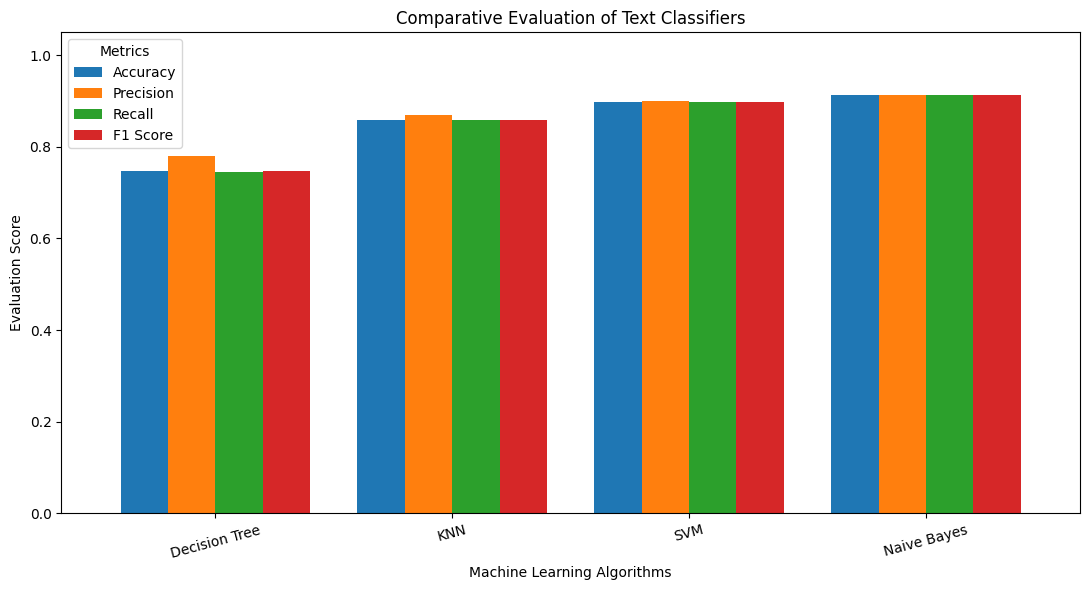

In [9]:
comparison.set_index("Classifier").plot(
    kind='bar',
    figsize=(11, 6),
    width=0.8
)

plt.title("Comparative Evaluation of Text Classifiers")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Evaluation Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

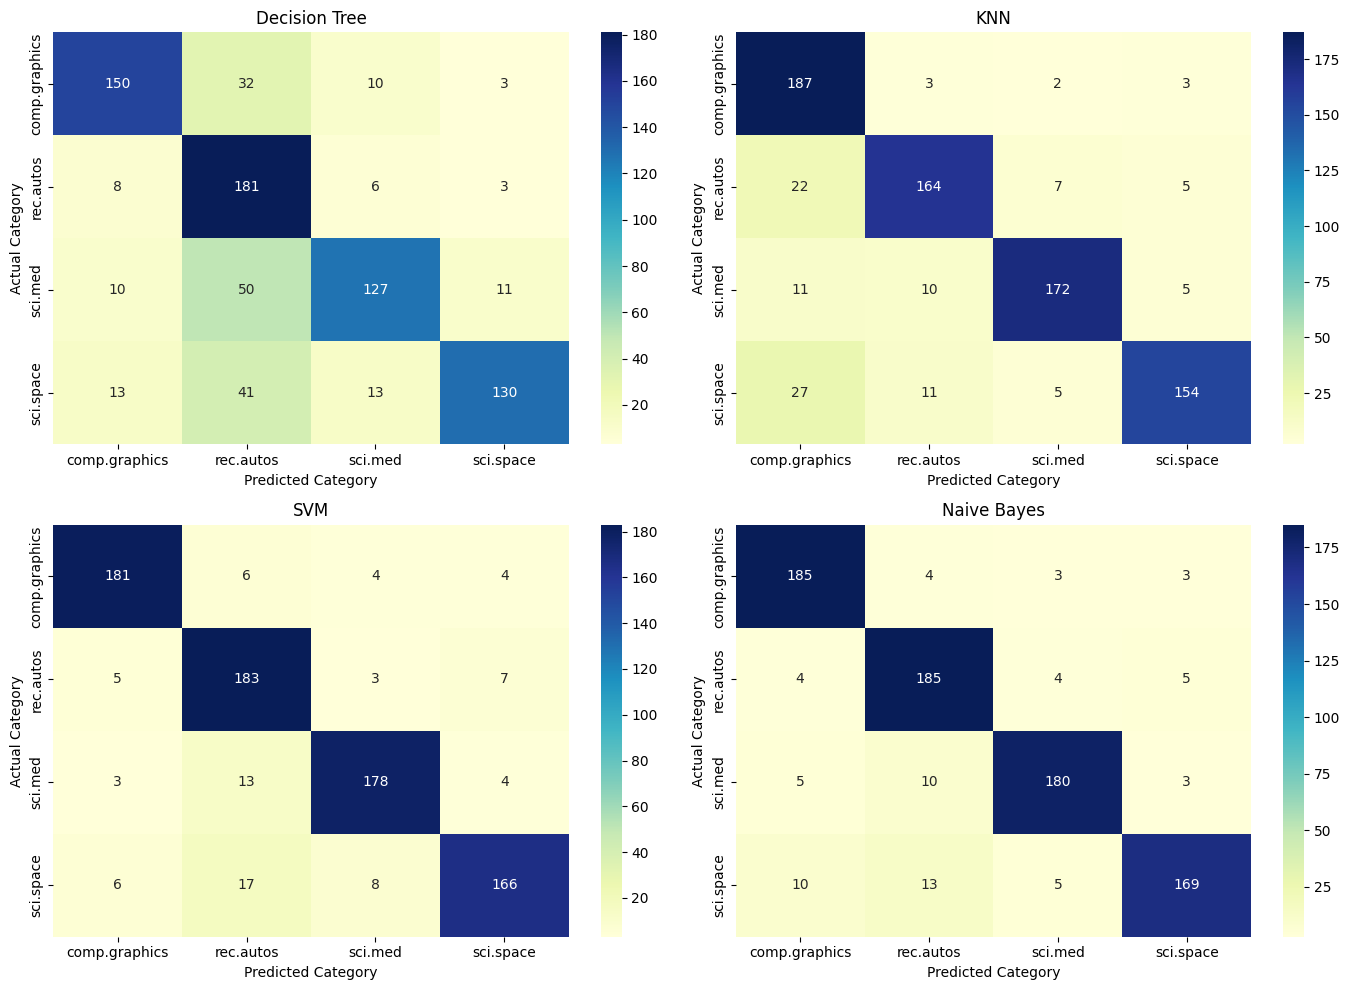

In [10]:
fig, plots = plt.subplots(2, 2, figsize=(14, 10))

for axis, (algorithm, predictions) in zip(
    plots.flatten(), model_predictions.items()
):

    matrix = confusion_matrix(test_labels, predictions)

    sns.heatmap(
        matrix,
        annot=True,
        fmt='d',
        cmap='YlGnBu',
        xticklabels=news_data.target_names,
        yticklabels=news_data.target_names,
        ax=axis
    )

    axis.set_title(algorithm)
    axis.set_xlabel("Predicted Category")
    axis.set_ylabel("Actual Category")

plt.tight_layout()
plt.show()

In [11]:
for algorithm, predictions in model_predictions.items():

    print("\n", "=" * 50)
    print("ALGORITHM:", algorithm)
    print("=" * 50)

    print(
        classification_report(
            test_labels,
            predictions,
            target_names=news_data.target_names,
            zero_division=0
        )
    )


ALGORITHM: Decision Tree
               precision    recall  f1-score   support

comp.graphics       0.83      0.77      0.80       195
    rec.autos       0.60      0.91      0.72       198
      sci.med       0.81      0.64      0.72       198
    sci.space       0.88      0.66      0.76       197

     accuracy                           0.75       788
    macro avg       0.78      0.75      0.75       788
 weighted avg       0.78      0.75      0.75       788


ALGORITHM: KNN
               precision    recall  f1-score   support

comp.graphics       0.76      0.96      0.85       195
    rec.autos       0.87      0.83      0.85       198
      sci.med       0.92      0.87      0.90       198
    sci.space       0.92      0.78      0.85       197

     accuracy                           0.86       788
    macro avg       0.87      0.86      0.86       788
 weighted avg       0.87      0.86      0.86       788


ALGORITHM: SVM
               precision    recall  f1-score   support



In [12]:
winner = comparison.loc[comparison["F1 Score"].idxmax()]

print("BEST CLASSIFIER:", winner["Classifier"])
print("Accuracy:", round(winner["Accuracy"], 4))
print("Precision:", round(winner["Precision"], 4))
print("Recall:", round(winner["Recall"], 4))
print("F1 Score:", round(winner["F1 Score"], 4))

BEST CLASSIFIER: Naive Bayes
Accuracy: 0.9124
Precision: 0.914
Recall: 0.9125
F1 Score: 0.9123


In [13]:
depth_values = [10, 30, 50, 100, None]

depth_results = []

for depth in depth_values:

    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=21
    )

    tree.fit(train_features, train_labels)

    predictions = tree.predict(test_features)

    score = precision_recall_fscore_support(
        test_labels,
        predictions,
        average='macro',
        zero_division=0
    )[2]

    depth_results.append({
        "Maximum Depth": str(depth),
        "Macro F1 Score": score
    })

depth_table = pd.DataFrame(depth_results)

display(depth_table.round(4))

,Maximum Depth,Macro F1 Score
0,10,0.5916
1,30,0.6837
2,50,0.7098
3,100,0.7476
4,None,0.7576


In [14]:
comparison.to_csv(
    "friend_classification_results.csv",
    index=False
)

depth_table.to_csv(
    "decision_tree_whatif_results.csv",
    index=False
)

print("Both experimental result files saved!")

Both experimental result files saved!
